# Машинное обучение, ФКН ВШЭ

## Практическое задание (Бонус). Разложение ошибки на смещение и разброс

### Общая информация

Дата выдачи: 12.12.2023

Мягкий дедлайн: 23:59MSK 24.12.2023

Жесткий дедлайн: 23:59MSK 24.12.2023

### Оценивание и штрафы
Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). Максимально допустимая оценка за работу — 6 баллов.

Сдавать задание после указанного срока сдачи нельзя. При выставлении неполного балла за задание в связи с наличием ошибок на усмотрение проверяющего предусмотрена возможность исправить работу на указанных в ответном письме условиях.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов (подробнее о плагиате см. на странице курса). Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке.

### Формат сдачи
Задания сдаются через систему anytask. Посылка должна содержать:
* Ноутбук homework-practice-07-Username.ipynb

Username — ваша фамилия и имя на латинице именно в таком порядке

### О задании

В этом задании вам предстоит воспользоваться возможностями бутстрапа для оценки смещения и разброса алгоритмов машинного обучения. Делать мы это будем на данных boston:

In [144]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

In [145]:
from sklearn.datasets import fetch_california_housing

In [146]:
boston = fetch_california_housing()

In [147]:
X = boston["data"][:1000]
y = boston["target"][:1000]

In [148]:
X.shape, y.shape

((1000, 8), (1000,))

### Вычисление bias и variance с помощью бутстрапа
На лекции была выведено следующая формула, показывающая, как можно представить ошибку алгоритма регрессии в виде суммы трех компонент:
$$
L(\mu) = 
    \mathbb{E}_{x, y}\bigl[\mathbb{E}_{X}\bigl[ (y - \mu(X)(x))^2 \bigr]\bigr] = 
$$
$$
    \underbrace{\mathbb{E}_{x, y}\bigl[(y - \mathbb{E}[y|x] )^2\bigr]}_{\text{шум}} + \underbrace{\mathbb{E}_{x}\bigl[(\mathbb{E}_{X}[\mu(X)(x)] - \mathbb{E}[y|x] )^2\bigr]}_{\text{смещение}} +
    \underbrace{\mathbb{E}_{x}\bigl[\mathbb{E}_{X}\bigl[(\mu(X)(x) - \mathbb{E}_{X}[\mu(X)(x)] )^2\bigr]\bigr]}_{\text{разброс}},
$$
* $\mu(X)$ — алгоритм, обученный по выборке $X = \{(x_1, y_1), \dots (x_\ell, y_\ell)\}$;
* $\mu(X)(x)$ — ответ алгоритма, обученного по выборке $X$, на объекте $x$;
* $\mathbb{E}_{X}$ — мат. ожидание по всем возможным выборкам;
* $\mathbb{E}_{X}[\mu(X)(x)]$ — "средний" ответ алгоритма, обученного по всем возможным выборкам $X$, на объекте $x$.
    
С помощью этой формулы мы можем анализировать свойства алгоритма обучения модели $\mu$, если зададим вероятностную модель порождения пар $p(x, y)$.

В реальных задачах мы, конечно же, не знаем распределение на парах объект - правильный ответ. Однако у нас есть набор семплов из этого распределения (обучающую выборка), и мы можем использовать его, чтобы оценивать математические ожидания. Для оценки мат. ожиданий по выборкам мы будем пользоваться бутстрэпом - методом генерации "новых" выборок из одной с помощью выбора объектов с возвращением. Разберем несколько шагов на пути к оценке смещения и разброса.

#### Приближенное вычисление интегралов
На занятиях мы разбирали примеры аналитического вычисления смещения и разброса нескольких алгоритмов обучения. Для большинства моделей данных и алгоритмов обучения аналитически рассчитать математические ожидания в формулах не удастся. Однако мат. ожидания можно оценивать приближенно. Чтобы оценить математическое ожидание $\mathbb{E}_{\bar z} f(\bar z)$ функции от многомерной случайной величины $\bar z = (z_1, \dots, z_d)$, $\bar z \sim p(\bar z)$, можно сгенерировать выборку из распределения $p(\bar z)$ и усреднить значение функции на элементах этой выборки:
$$\mathbb{E}_{\bar z} f(z) = \int f(\bar z) p(\bar z) d \bar z \approx \frac 1 m \sum_{i=1}^m f(\bar z_i), \, \bar z_i \sim p(\bar z), i = 1, \dots, m.$$

Например, оценим $\mathbb{E}_z z^2,$ $z \sim \mathcal{N}(\mu=5, \sigma=3)$ (из теории вероятностей мы знаем, что
$\mathbb{E}_z z^2 = \sigma^2 + \mu^2 = 34$):

In [149]:
z = np.random.normal(loc=5, scale=3, size=1000)
(z**2).mean()

np.float64(30.992416814895847)

#### Оценивание $\mathbb{E}_{x, y}$
Оценить мат. ожидания по $x$ и по $x, y$, встречающиеся во всех трех компонентах разложения, несложно, потому что у нас есть выборка объектов из распределения данных $p(x, y)$:
$$ \mathbb{E}_{x} f(x) \approx \frac 1 N \sum_{i=1}^N f(x_i), \quad
\mathbb{E}_{x, y} f(x, y) \approx \frac 1 N \sum_{i=1}^N f(x_i, y_i),$$
где $N$ - число объектов в выборке, $\{(x_i, y_i)\}_{i=1}^N$ - сама выборка. 

#### Оценивание $\mathbb{E}_X$ с помощью бутстрапа
Чтобы оценить мат. ожидание по $X$, нам понадобится выборка из выборок:
$$\mathbb{E}_X f(X) \approx \frac 1 s \sum_{j=1}^s f(X_j),$$
где $X_j$ - $j$-я выборка. Чтобы их получить, мы можем воспользоваться бутстрапом - методом генерации выборок на основе выбора объектов с возвращением. Чтобы составить одну выборку, будем $N$ раз выбирать индекс объекта $i \sim \text{Uniform}(1 \dots N)$ и добавлять $i$-ю пару (объект, целевая переменная) в выборку. В результате в каждой выборке могут появиться повторяющиеся объекты, а какие-то объекты могут вовсе не войти в некоторые выборки.

#### Итоговый алгоритм оценки смещения и разброса алгоритма $a$
1. Сгенерировать $s$ выборок $X_j$ методом бутстрапа.
1. На каждой выборке $X_j$ обучить алгоритм $a_j$.
1. Для каждой выборки $X_j$ определить множество объектов $T_j$, не вошедших в нее (out-of-bag). Вычислить предсказания алгоритма $a_j$ на объектах $T_j$. 

Поскольку у нас есть только один ответ для каждого объекта, мы будем считать шум равным 0, а $\mathbb{E}[y|x]$ равным имеющемуся правильному ответу для объекта $x$. 

Итоговые оценки:
* Смещение: для одного объекта - квадрат разности среднего предсказания и правильного ответа. Среднее предсказание берется только по тем алгоритмам $a_j$, для которых этот объект входил в out-of-bag выборку $T_j$. Для получения общего смещения выполнить усреденение смещений по объектам.
* Разброс: для одного объекта - выборочная дисперсия предсказаний алгоритмов $a_j$, для которых этот объект входил в out-of-bag выборку $T_j$. Для получения общего разброса выполнить усреденение разбросов по объектам.
* Ошибка $L$: усреднить квадраты разностей предсказания и правильного ответа по всем выполненным предсказаниям для всех объектов.

В результате должно получиться, что ошибка приблизительно равна сумме смещения и разброса!

Алгоритм также вкратце описан по [ссылке](https://web.engr.oregonstate.edu/~tgd/classes/534/slides/part9.pdf) (слайды 19-21).

__1. (1.5 балла)__

Реализуйте описанный алгоритм. Обратите внимание, что если объект не вошел ни в одну из out-of-bag выборок, учитывать его в вычислении итоговых величин не нужно. Как обычно, разрешается использовать только один цикл - по выборкам (от 0 до num_runs-1).

In [150]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import  mean_squared_error

def compute_biase_variance(regressor, X, y, num_runs=1000, num_elements=700):
    """
    :param regressor: sklearn estimator with fit(...) and predict(...) method
    :param X: numpy-array representing training set ob objects, shape [n_obj, n_feat]
    :param y: numpy-array representing target for training objects, shape [n_obj]
    :param num_runs: int, number of samples (s in the description of the algorithm)
    
    :returns: bias (float), variance (float), error (float) 
    each value is computed using bootstrap
    """
    ### your code here

    idx = np.random.randint(0, X.shape[0] - 1, size=(num_runs, num_elements))
    all_idx = np.arange(0, X.shape[0], 1)
    loss_idx = [0, 0]
    preds_power_sum = np.array([(0, 0, 0) for i in range(X.shape[0])]).astype(float)

    for i in idx:
        test_idx = list(set(all_idx) - set(i))
        regressor.fit(X[i], y[i])
        preds = regressor.predict(X[test_idx])

        preds_power_sum[test_idx, 0] += 1
        preds_power_sum[test_idx, 1] += preds
        preds_power_sum[test_idx, 2] += preds ** 2

        loss_idx[0] += ((y[test_idx] - preds) ** 2).sum()
        loss_idx[1] += len(test_idx)
        
    mask = (preds_power_sum[:, 0] > 0)
    mean_preds = preds_power_sum[mask, 1] / preds_power_sum[mask, 0]
    mean_preds_sq = preds_power_sum[mask, 2] / preds_power_sum[mask, 0]

    var = (mean_preds_sq - mean_preds ** 2).mean()

    bias = ((preds_power_sum[mask, 1] / preds_power_sum[mask, 0] - y[mask]) ** 2).mean()
    loss = loss_idx[0] / loss_idx[1]
        
    return bias, var, loss
    

model = LinearRegression()
compute_biase_variance(model, X, y, num_runs=50)

(np.float64(0.3026751353001082),
 np.float64(0.010656339720909428),
 np.float64(0.31461628214695225))

__2. (0 баллов)__

Оцените смещение, разброс и ошибку для трех алгоритмов с гиперпараметрами по умолчанию: линейная регрессия, решающее дерево, случайный лес.

In [151]:
### your code here
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

models = {
    "linreg" : LinearRegression(),
    "dtree" : DecisionTreeRegressor(),
    "rforest" : RandomForestRegressor()
}

for key, val in models.items():
    print(key)
    print(compute_biase_variance(val, X, y, num_runs=70))

linreg
(np.float64(0.2943769301489946), np.float64(0.0066818700561681555), np.float64(0.300796312629097))
dtree
(np.float64(0.18418293883772485), np.float64(0.184705344941146), np.float64(0.36682284581567065))
rforest
(np.float64(0.1828677809599176), np.float64(0.024685647289487064), np.float64(0.2106162867167629))


__3. (0.5 баллов)__
Проанализируйте полученный результат. Согласуются ли полученные результаты с теми, что мы обсуждали на занятиях (с комментарием)?

__Your answer here:__ Да. У линрега больше смещение и меньше разброс, когда у деревьев меньше смещение и больше разброс. Также большое количество деревьев в ансамбле сильно уменьшает разброс модели

In [152]:
from sklearn.base import clone

#Sklearn.ensemble bagging regressor/classifier
def compute_biase_variance_bagging(regressor, X, y, num_runs=1000, num_elements=700, num_models = 3):
    """
    :param regressor: sklearn estimator with fit(...) and predict(...) method
    :param X: numpy-array representing training set ob objects, shape [n_obj, n_feat]
    :param y: numpy-array representing target for training objects, shape [n_obj]
    :param num_runs: int, number of samples (s in the description of the algorithm)
    
    :returns: bias (float), variance (float), error (float) 
    each value is computed using bootstrap
    """
    ### your code here

    idx = np.random.randint(0, X.shape[0] - 1, size=(num_runs, num_elements))
    all_idx = np.arange(0, X.shape[0], 1)
    loss_idx = [0, 0]
    preds_power_sum = np.array([(0, 0, 0) for i in range(X.shape[0])]).astype(float)
    models = []

    for i in range(num_models):
        models.append(clone(regressor))

    for i in idx:
        test_idx = list(set(all_idx) - set(i))

        preds = 0
        for model in models:
            model.fit(X[i], y[i])
            preds += model.predict(X[test_idx])
        preds /= num_models

        preds_power_sum[test_idx, 0] += 1
        preds_power_sum[test_idx, 1] += preds
        preds_power_sum[test_idx, 2] += preds ** 2

        loss_idx[0] += ((y[test_idx] - preds) ** 2).sum()
        loss_idx[1] += len(test_idx)
        
    mask = (preds_power_sum[:, 0] > 0)
    mean_preds = preds_power_sum[mask, 1] / preds_power_sum[mask, 0]
    mean_preds_sq = preds_power_sum[mask, 2] / preds_power_sum[mask, 0]

    var = (mean_preds_sq - mean_preds ** 2).mean()

    bias = ((preds_power_sum[mask, 1] / preds_power_sum[mask, 0] - y[mask]) ** 2).mean()
    loss = loss_idx[0] / loss_idx[1]
        
    return bias, var, loss
    

models = {
    "linreg" : LinearRegression(),
    "dtree" : DecisionTreeRegressor(),
    "rforest" : RandomForestRegressor()
}

for key, val in models.items():
    print(key)
    print(compute_biase_variance_bagging(val, X, y, num_runs=70))

linreg
(np.float64(0.2976061527185042), np.float64(0.008688433179922232), np.float64(0.30388345906711894))
dtree
(np.float64(0.1869529371961366), np.float64(0.16890951704280072), np.float64(0.3568858974306328))
rforest
(np.float64(0.18379901185508793), np.float64(0.023606851317236614), np.float64(0.20759947519424563))


__4. (0.5 баллов)__
Постройте бэггинг над всеми тремя моделями (линейная регрессия, решающее дерево, случайный лес). Вспомните обсуждение с лекции о том, во сколько раз в теории бэггинг уменьшает разброс базового алгоритма. Выполняется ли это в ваших экспериментах? Если нет, поясните, почему.

__Your answer here:__ Линейная регрессия строит примерно одинаковый плоскости на тех же данных. Деревья на тех же данных тоже сильно скореллированы. На случайном лесе изменения незначительны, так как случайный лес это уже бэггинг

### Визуализация предсказаний базовых алгоритмов бэггинга

В материалах лекций можно найти изображение, похожее на мишень - визуализация алгоритмов с разным смещением и разным разбросом. В центре "мишени" - правильный ответ, а "попадания" - предсказания алгоритмов, обученных по разным выборкам. Построим похожее изображение на наших данных для трех алгоритмов. Наши "мишени" будут одномерными, потому что мы решаем задачу одномерной регрессии.

__5. (1.5 балла)__

Реализуйте функцию plot_predictions. Она должна выполнять следующие действия:
1. Случайно выбрать num_test_objects пар объект-целевая переменная из выборки X, y. Получится две выборки: маленькая X_test, y_test (выбранные тестовые объекты) и X_train, y_train (остальные объекты).
1. Сгенерировать num_runs выборок методом бутстарапа из X_train, y_train. На каждой выборке обучить алгоритм regressor и сделать предсказания для X_test.
1. Нарисовать scatter-график. По оси абсцисс - объекты тестовой выборки (номера от 0 до num_test_objects-1), по оси ординат - предсказания. В итоге получится num_test_objects столбиков с точками. Для каждого тестового объекта надо отметить одним цветом все предсказания для него, а также черным цветом отметить правильный ответ.
1. Подпишите оси и название графика (аргумент title).

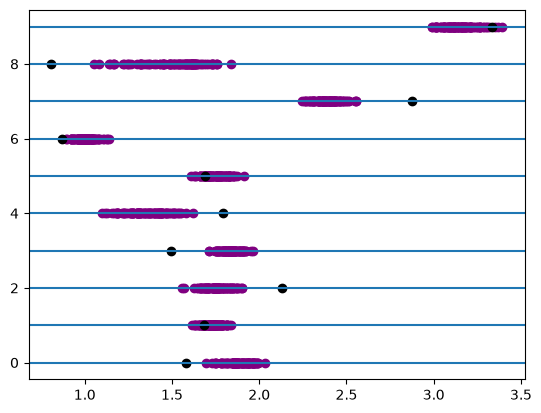

In [153]:
def plot_predictions(regressor, X, y, num_runs=100, num_test_objects=10, num_models = 10, num_elements = 700, title=""):
    """
    plot graphics described above
    """
    ### your code here

    plt.title(title)
    idx = np.arange(0, X.shape[0], 1)
    test_idx = np.random.choice(np.arange(0, X.shape[0]), size=10, replace=False)
    idx_train = np.setdiff1d(idx, test_idx)

    order = np.arange(0, num_test_objects, 1)
    for i in range(num_test_objects):
        plt.axhline(y=i)
    
    for i in range(num_runs):
        train_sample = np.random.choice(idx_train, size=num_elements, replace=True)
        regressor.fit(X[train_sample], y[train_sample])
        preds = regressor.predict(X[test_idx])
        plt.scatter(preds, order, color='purple')
    plt.scatter(y[test_idx], order, color='black')

plot_predictions(model, X, y)

__6. (0 баллов)__

Нарисуйте графики для линейной регрессии, решающего дерева и случайного леса. Нарисуйте три графика в строчку (это можно сделать с помощью plt.subplot) с одинаковой осью ординат (это важно для понимания масштаба разброса у разных алгоритмов):

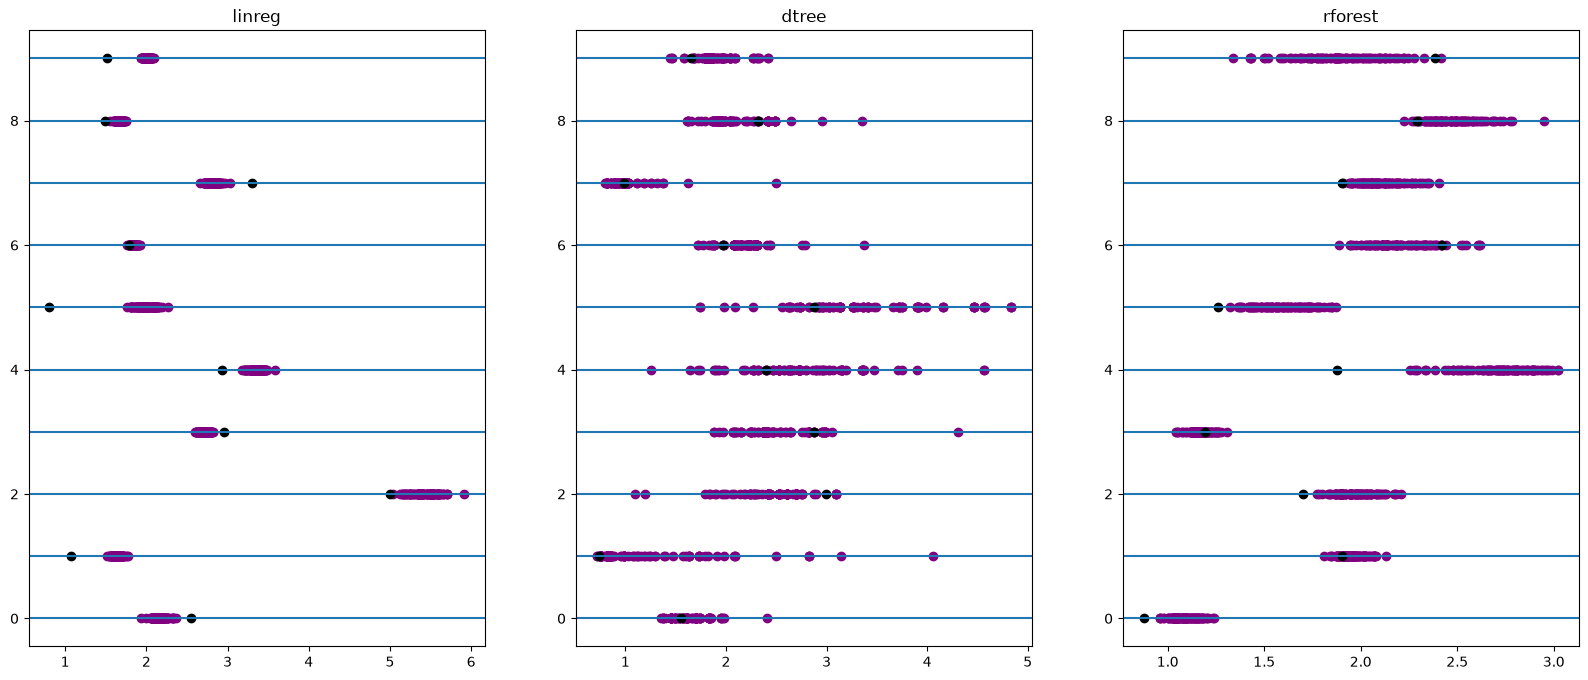

In [154]:
### your code here
fig, ax = plt.subplots(1, 3, figsize=(20, 8))

cur = 0
for key, val in models.items():
    plt.sca(ax[cur])
    cur += 1
    plot_predictions(val, X, y, title=key)

__7. (0.5 баллов)__

Для каждого графика прокомментируйте, как он характеризует смещение и разброс соответствующего алгоритма. 

__Your answer here:__ Линрег маленький разброс, большое смещение. Дерево большой разброс, небольшое смещение. Лес меньший разброс(чем у дерева), небольшое смещение.

### Изменение bias и variance при изменении гиперпараметров

__8. (0 баллов)__

Постройте графики зависимости смещения и разброса от гиперпараметров решающего дерева max_depth (от 1 до 10) и max_features (от 1 до X.shape[1]):

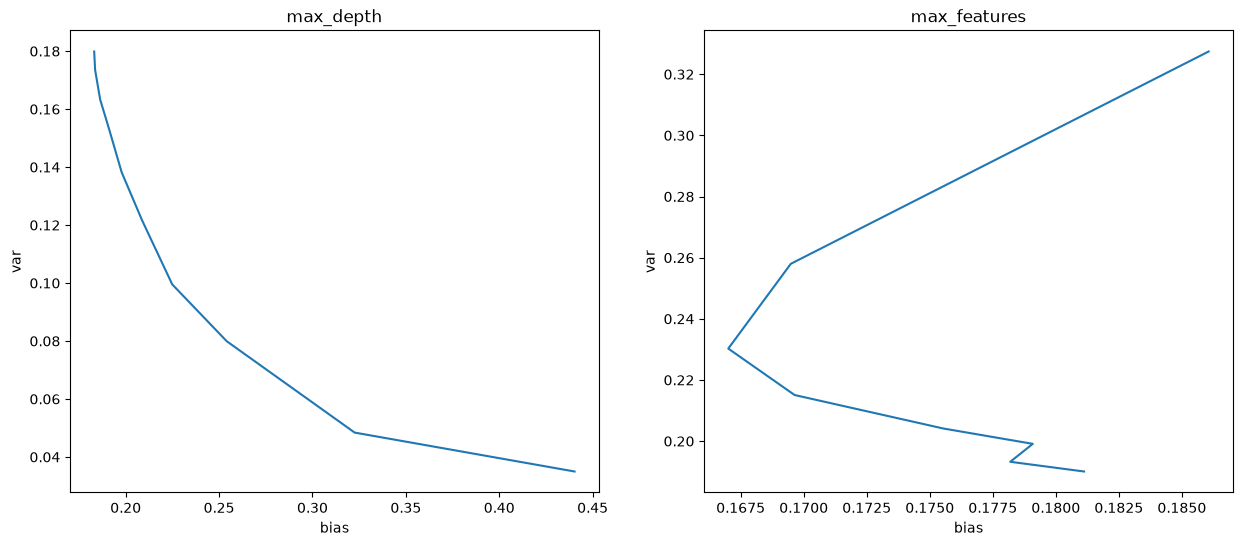

In [156]:
### your code here
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
max_depth = np.arange(1, 11, 1)
max_features = np.arange(1, X.shape[1] + 1, 1)
plt.sca(ax[0])
plt.xlabel("bias")
plt.ylabel("var")
plt.title("max_depth")

bias, var = [], []
for i in max_depth:
    model = DecisionTreeRegressor(max_depth=i)
    b, v, _ = compute_biase_variance(model, X, y)
    bias.append(b)
    var.append(v)
plt.plot(bias, var)

plt.sca(ax[1])
plt.xlabel("bias")
plt.ylabel("var")
plt.title("max_features")

bias, var = [], []
for i in max_features:
    model = DecisionTreeRegressor(max_features=i)
    b, v, _ = compute_biase_variance(model, X, y)
    bias.append(b)
    var.append(v)
plt.plot(bias, var)


__9. (0 баллов)__

Постройте графики зависимости смещения и разброса от n_estimators (по сетке 2**np.arange(1, 10)) для случайного леса и градиентного бустинга:

END_1


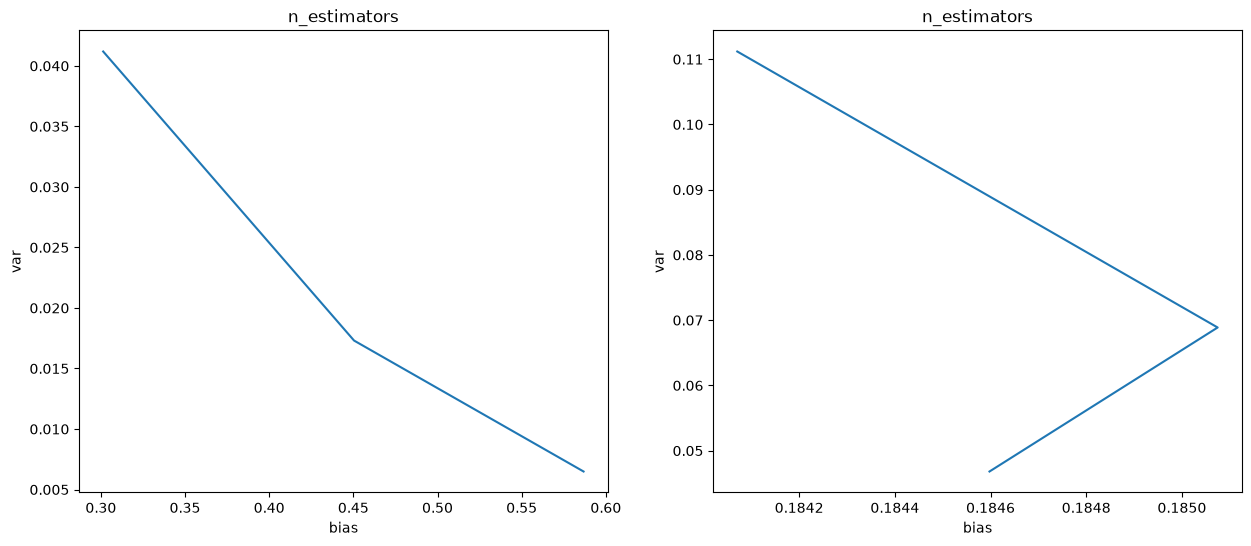

In [ ]:
### your code here
from sklearn.ensemble import GradientBoostingRegressor

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
n_estimators = 2 ** np.arange(1, 4) #Не хочу долго компилить
plt.sca(ax[0])
plt.xlabel("bias")
plt.ylabel("var")
plt.title("n_estimators")

bias, var = [], []
for i in n_estimators:
    model = GradientBoostingRegressor(n_estimators=i, max_depth=10)
    b, v, _ = compute_biase_variance(model, X, y)
    bias.append(b)
    var.append(v)
plt.plot(bias, var)
print("END_1")

plt.sca(ax[1])
plt.xlabel("bias")
plt.ylabel("var")
plt.title("n_estimators")

bias, var = [], []
for i in n_estimators:
    model = RandomForestRegressor(max_depth=10, n_estimators=i) #Ещё немного ускорить
    b, v, _ = compute_biase_variance(model, X, y)
    bias.append(b)
    var.append(v)
plt.plot(bias, var)


__10. (1.5 балла)__

Прокомментируйте графики (всего 4 графика): почему они имеют такой вид.

__Your answer here:__

На первом графике видно, что снижение смещения ведет к увеличению вариативности (модель переобучается).

На втором графике значение модель начинает переобучаться с какого-то момента, и снова снижение смещения ведет к увеличению вариативности

На третьем графике такое же снижение что и на первом

На четвёртом смещение колеблется, но уменьшается разброс

__11. Бонус (0.1 балла)__


Прикрепите фотографию того, как вы начали эту зиму ❄️

__Your answer here:__